In [1]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

print("Ready! OSMnx version", ox.__version__)
print("Files in data/:", sorted(os.listdir(r"C:\Users\Aaron\Downloads\lab5_data")))

#Install everything I will need for the lab as recomended in the setup

Ready! OSMnx version 1.5.0
Files in data/: ['data']


---
# Part 2 · Is the city growing, or is the map growing?

OpenStreetMap (OSM) keeps every version of every feature since 2007. The **ohsome API** lets us ask: *how many buildings were on the map on 1 January of each year?*

But be careful: OSM tells us when something was **mapped**, not when it was **built**.

### 2.1 Your ohsome API key

1. Sign up for free at **https://account.heigit.org/signup**
2. Create an API key and copy it
3. Run the cell below and paste the key into the box (it is hidden and not saved in the notebook)

**Challenge 1** — Change `BBOX` to another place (find coordinates at https://bboxfinder.com, choose the format *west, south, east, north*). Does the pattern repeat?. 


In [2]:
API_KEY = getpass.getpass("Paste your ohsome API key ")

Paste your ohsome API key  ········


In [3]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-3.895683, 55.950161, -3.022614, 56.195245]          #Set Box coordinates to Dunfermline

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,  
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}} #Filtering the dates from 2008-2026
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]   
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")  
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

#Replicated given code, just changing bbox to Dunfermline coordinates 

,Buildings (count),Residential streets (km)
2008,42,266.145
2009,122,456.213
2010,478,611.400
2011,4984,1538.979
2012,8040,1597.565
2013,12191,1623.809
2014,15352,1636.598
2015,30847,1625.577
2016,48065,1644.080
2017,69377,1672.181


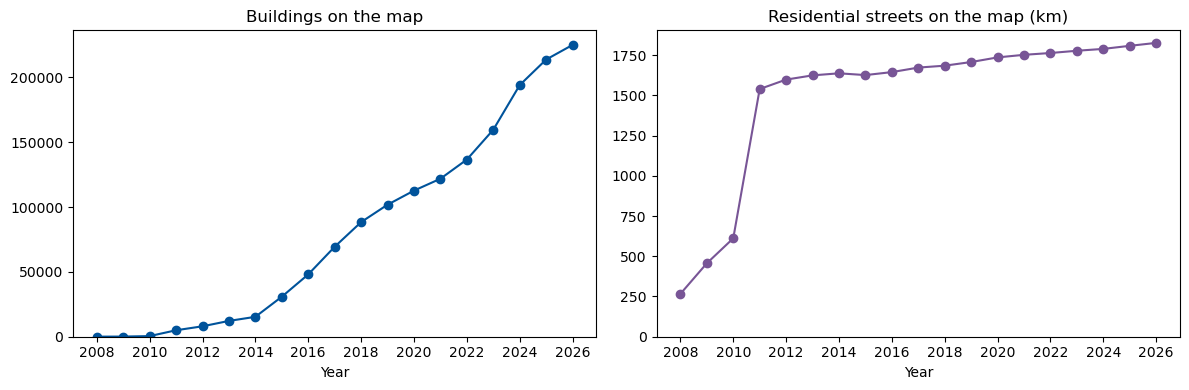

Change from 2012 to 2026 (%):
Buildings (count)           2699.0
Residential streets (km)      14.0
dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100 
print("Change from 2012 to 2026 (%):")
print(change.round(0))

In [5]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-3.26, 55.94, -3.16, 55.99]          #North Edinburgh coordinates 

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

,Buildings (count),Residential streets (km)
2008,45,147.460
2009,128,206.295
2010,784,224.165
2011,4860,233.666
2012,6522,233.881
2013,8868,235.602
2014,10904,232.541
2015,20226,233.320
2016,29225,236.674
2017,40761,238.366


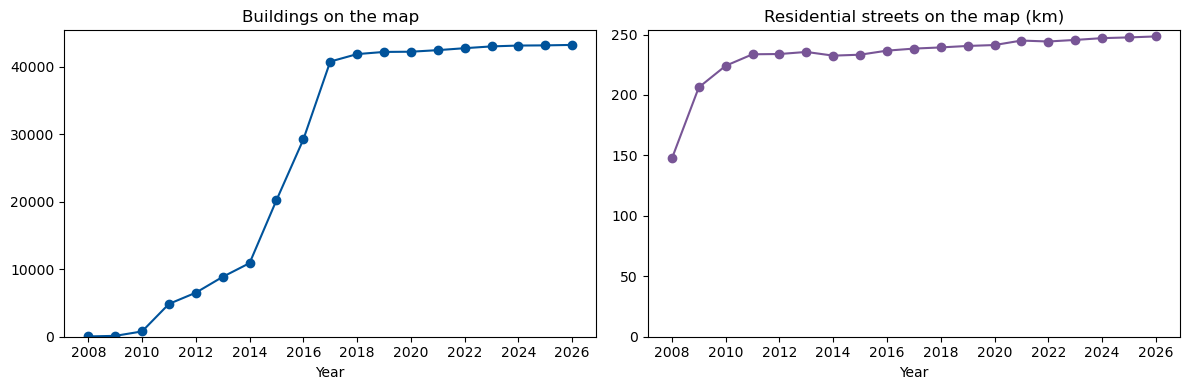

Change from 2012 to 2026 (%):
Buildings (count)           563.0
Residential streets (km)      6.0
dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

The pattern between our graphs is similar with residential streets, as the Edinburgh map sees a sharp rise in 2008, while the Dunfermline map sees a sharp rise in 2010. While buildings on maps is far more steadily rising for Dunfermline compared to Edinbirgh steep rise and eventual leveling. 


---

## Part 3 · Three ways to measure access to food shops (Dundee)

| Measure | Question |
|---|---|
| **Nearest** | How many minutes to the closest food shop? |
| **Cumulative** | How many food shops within a 10-minute walk? |
| **Gravity** | How many food shops are within reach, with nearer shops counting more? |

### 3.1 Load the walk network and the food shops

Both come from OpenStreetMap and are in the `data` folder: the **walk network** within 3 km of central Dundee, and four kinds of **services** (food shops, pharmacies, GPs, schools).

**Challenge 2.1** — Measure access to something else. In 2.1, change `"Food shop"` to `"Pharmacy"`, `"GP"` or `"School"` and run Part 2 again.

**Challenge 2.2** — Try `BETA = 0.14` (half weight at 5 minutes). Who might this steeper decay represent?

In [29]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml(r"C:\lab5_data\data\dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file(r"C:\lab5_data\data\dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

shops = dundee_services[dundee_services["service"] == "Food shop"]
print(len(nodes), "street junctions and", len(shops), "food shops")

#Replicated code, kept shops here as otherwise openstreetmaps food shops will show as 0 later on in challenge 4.

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 104 food shops


In [ ]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml(r"C:\lab5_data\data\dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file(r"C:\lab5_data\data\dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

GP = dundee_services[dundee_services["service"] == "GP"]
print(len(nodes), "street junctions and", len(GP), "GP")

#Replicated code, subsituting food shops with GP's

In [8]:
GP["node"] = ox.distance.nearest_nodes(G, GP.geometry.x, GP.geometry.y)
GP[["name", "node"]].head()

#Producing a table with GP names and geometries as to enable maping later 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\geopandas\geodataframe.py:1543: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


,name,node
123,Erskine Practice,12630357271
124,Mill Practice,12630357271
125,Hillbank Health Centre,12730677680
126,Terra Nova,12480649121
127,Hutcheson Podiatry,6651632775


In [9]:
nearest = nx.multi_source_dijkstra_path_length(G, set(GP["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

BETA = 0.14 #half weight at 5 minutes 

cumulative = {node: 0 for node in G.nodes}     
gravity = {node: 0.0 for node in G.nodes}

for GP_node in GP["node"]:
    distances = nx.single_source_dijkstra_path_length(G, GP_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

#Replicated code, to calculate whether the junction is within 10 minutes of the shop, as well as a weight that gets smaller with distance. 

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,16.01,0.70,0.60
std,10.11,1.24,0.69
min,0.00,0.00,0.00
25%,7.36,0.00,0.05
50%,13.72,0.00,0.30
75%,24.26,1.00,1.02
max,42.92,5.00,3.88


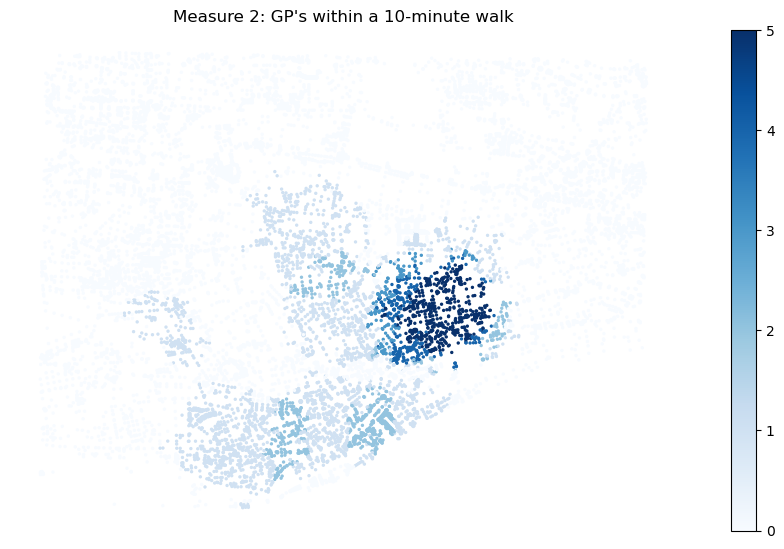

In [10]:
fig, axes = plt.subplots(1, figsize=(14, 6.5))

nodes.plot(ax=axes, column="cumulative", cmap="Blues", markersize=2, legend=True)

axes.set_title("Measure 2: GP's within a 10-minute walk")

axes.set_axis_off()
plt.show()

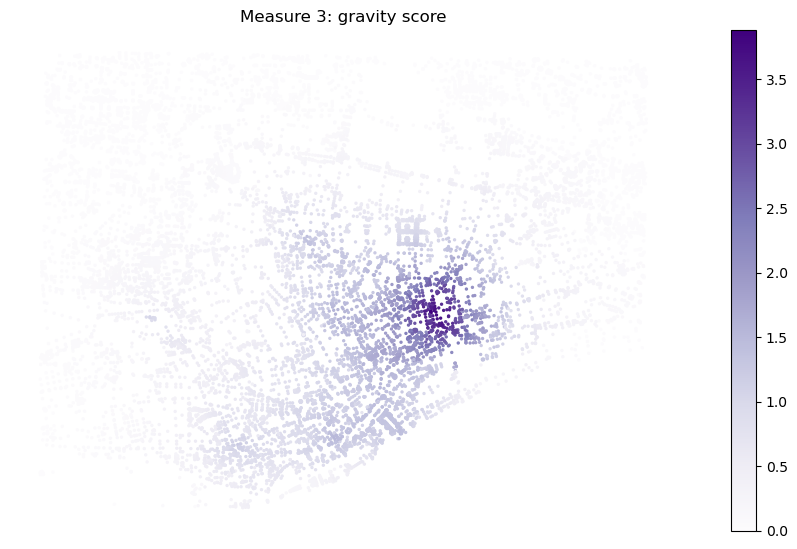

In [11]:
fig, axes = plt.subplots(1, figsize=(14, 6.5))

nodes.plot(ax=axes, column="gravity", cmap="Purples", markersize=2, legend=True)
axes.set_title("Measure 3: gravity score")

axes.set_axis_off()
plt.show()

Steeper decay will better represent people less willing or able to travel further distances, e.g. elderly or those with disabilities.

---
## Part 4 · Does the data source change the answer? Overture Maps vs OpenStreetMap (Dundee)

**Overture Maps** is an open map dataset built by a foundation of companies including Amazon, Meta, Microsoft and TomTom. Its **places** layer (shops, cafés, clinics and more) combines several sources, and every place has a **confidence** score. It is stored on cloud storage that anyone can read, which makes it quick and reliable to download.

We now repeat Part 2's *nearest food shop* measure with Overture's shops instead of OSM's, using **the same OSM walk network**. If the answers differ, the difference comes from the data, not the method.

### 4.1 Download Overture places for Dundee

We ask for every place inside a box around central Dundee: `(west, south, east, north)` in longitude/latitude. The result arrives as a table, and the geometry comes in a compact format (WKB) that we turn into points.

**Challenge 3.1** — Change the confidence threshold in 3.3 from `0.5` to `0.8`. How many Overture shops are left, and how does the comparison table change?

**Challenge 3.2** — Look at the category list in 3.2 again and pick another service, for example `pharmacy`. Change the words in `str.contains(...)` and compare with the OSM pharmacies (`dundee_services`) from Part 2.

In [18]:
import overturemaps

DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

print(len(places), "Overture places in Dundee")

6657 Overture places in Dundee


In [22]:
places["basic_category"].value_counts().head(60)

#Examine key words within basic category to identify what words can be used to represent food places

basic_category
personal_or_beauty_service             510
home_service                           393
restaurant                             269
automotive_service                     230
professional_service                   218
hardware_home_and_garden_store         198
fashion_and_apparel_store              187
bar                                    176
real_estate_service                    142
food_and_beverage_store                141
financial_service                      126
convenience_store                      125
wellness_service                        99
casual_eatery                           98
corporate_or_business_office            87
social_or_community_service             81
christian_place_of_worship              77
design_service                          71
civic_organization                      71
event_or_party_service                  70
manufacturer                            68
auto_dealer                             68
fast_food_restaurant                   

In [31]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.8)]

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

#utalised labels that represent food paces in str.contains, adjusted confidence to 0.8, indicating more selectiveness

basic_category
convenience_store    90
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      90


In [35]:
nearest = nx.multi_source_dijkstra_path_length(G, set(GP["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED
#Taken code from prior excercise to enable nearest function, nearest min. 

In [36]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

#

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\geopandas\geodataframe.py:1543: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


,OpenStreetMap,Overture
Median minutes to nearest food shop,13.7,4.7
% of junctions within 10 minutes,37.7,81.9


In [37]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.5)]

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

#Confidence more lenient

basic_category
convenience_store    121
Name: count, dtype: int64

Food shops in OpenStreetMap: 0
Food shops in Overture:      121


In [38]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

#created table to display difference betwen overture and openstreet map data depending on confidence.

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\geopandas\geodataframe.py:1543: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


,OpenStreetMap,Overture
Median minutes to nearest food shop,13.7,4.1
% of junctions within 10 minutes,37.7,87.7


Overture adjusts as a lower confidence threshold means more shops will be included hence 0.5 has higher overture numbers.

In [40]:
pharmacies = dundee_services[
    dundee_services["service"] == "Pharmacy"
].copy()

In [45]:
places["basic_category"].value_counts().head(60)

basic_category
personal_or_beauty_service             510
home_service                           393
restaurant                             269
automotive_service                     230
professional_service                   218
hardware_home_and_garden_store         198
fashion_and_apparel_store              187
bar                                    176
real_estate_service                    142
food_and_beverage_store                141
financial_service                      126
convenience_store                      125
wellness_service                        99
casual_eatery                           98
corporate_or_business_office            87
social_or_community_service             81
christian_place_of_worship              77
design_service                          71
civic_organization                      71
event_or_party_service                  70
manufacturer                            68
auto_dealer                             68
fast_food_restaurant                   

In [42]:
is_pharmacy = places["basic_category"].str.contains("pharmacy", case=False, na=False)
overture_pharmacies = places[is_pharmacy & (places["confidence"] >= 0.5)].copy()

print(overture_pharmacies["basic_category"].value_counts())
print()
print("OSM pharmacies:", len(pharmacies))
print("Overture pharmacies:", len(overture_pharmacies))

#replicated similar logic as before but substituting pharmacy, chose to only use str. pharmacy as hospital, clinics etc, didnt seem suitable.

basic_category
pharmacy_and_drug_store    34
Name: count, dtype: int64

OSM pharmacies: 19
Overture pharmacies: 34


In [46]:
overture_pharmacies["node"] = ox.distance.nearest_nodes(G, overture_pharmacies.geometry.x, overture_pharmacies.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_pharmacies["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest pharmacy", "% of junctions within 10 minutes"])
comparison.round(2)

,OpenStreetMap,Overture
Median minutes to nearest pharmacy,13.72,7.29
% of junctions within 10 minutes,37.68,69.67


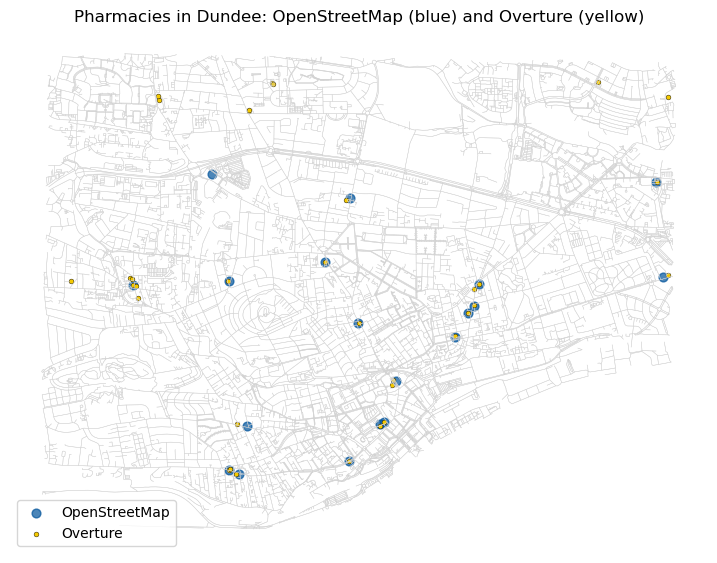

In [52]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
pharmacies.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_pharmacies.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacies in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

#Map comparing both OSM and Overture locations for Pharmacies

Overture differs from OSM evidently here, with certain overtures not being recorded on OSM. 

## Part 5 · Is this a 15-minute neighbourhood? (Glasgow)

A **15-minute neighbourhood** gives residents everyday services within:
- a **15-minute walk** (about **1.2 km**), or
- a **20-minute cycle** (about **5 km**)

We check five essential services for every residential street junction in Glasgow's West End.

### 5.1 The area and the services

**Challenge 4** — Scotland's local living goal is about 10 minutes each way. Change `WALK_LIMIT` to `800` and run 4.4 and 4.5 again. How many homes still reach all five services?

In [53]:
GLASGOW = (56.3960, -3.4370)       # Glasgow West End
AREA = 1500                        # metres: the neighbourhood we study
WALK_LIMIT = 800                   # 10 minutes walking
BIKE_LIMIT = 5000                  # 20 minutes cycling

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

#Adjusted walking limit to 800

In [54]:
G_walk = ox.load_graphml(r"C:\lab5_data\data\perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

G_bike = ox.load_graphml(r"C:\lab5_data\data\perth_bike.graphml")
G_bike = ox.project_graph(G_bike, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walk), "junctions | Bike network:", len(G_bike), "junctions")

#Downloading walk/bike networks

Walk network: 6595 junctions | Bike network: 9236 junctions


In [55]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file(r"C:\lab5_data\data\perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([GLASGOW[1]], [GLASGOW[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes), "residential junctions in the neighbourhood")

#Junctions enable us to identify rough;u where street intersections occur used to appricimate locations for where people live.

1067 residential junctions in the neighbourhood


In [56]:
services = gpd.read_file(r"C:\lab5_data\data\perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bike, homes.geometry.x, homes.geometry.y)   # the same homes on the bike network

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bike, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bike, set(bike_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    homes[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

#identifying services to enable measuring with networks and junctions. 

School               31 found
Food shop            48 found
Healthcare           29 found
Park                 28 found
Public transport    464 found


In [57]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 15-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 20-min cycle"] = [(homes[s + " bike (m)"] <= BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

#calculation carried out finding out average percentages. 

,% homes within 15-min walk,% homes within 20-min cycle
School,65.0,100.0
Food shop,77.0,100.0
Healthcare,68.0,100.0
Park,65.0,100.0
Public transport,100.0,100.0


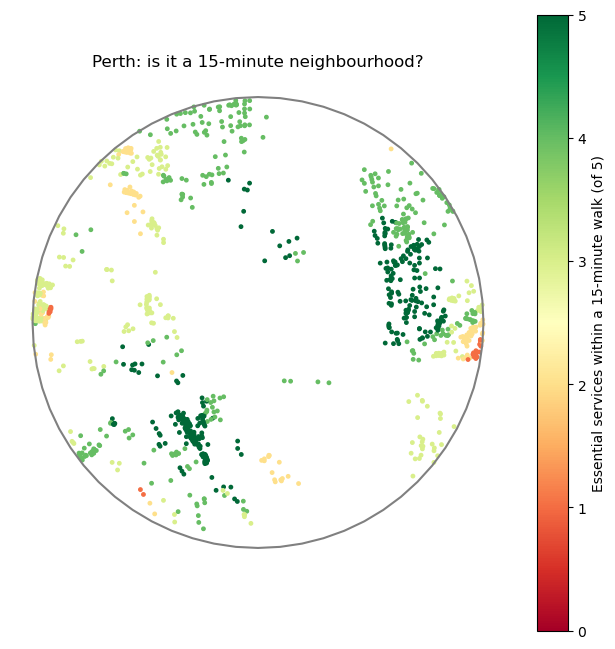

30% of residential junctions reach all 5 services on foot


In [58]:
homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 15-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 15-minute neighbourhood?")
ax.set_axis_off()
plt.show()

print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

#Great map to see where access to essential services lack. 

30% now only reach all 5 services comparitively to 85% for 1200 walk limit

## Part 6 · Drawing isochrones (Glasgow)

An **isochrone** is the area you can reach within a given time. We draw them in two ways:
1. **from a home**: what can one resident reach?
2. **from the services**: which areas are covered, and where are the gaps?

### 6.1 A small function that draws an isochrone

It takes the network, a starting junction and a distance. It keeps the streets reachable within that distance and turns them into a shape by drawing a 50 m band around them.

**Challenges 5** — Change the services in 5.4 from `"Healthcare"` to `"Food shop"` or `"School"`. Where are the biggest gaps?

In [59]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)

    return unary_union(list(streets.buffer(50)))

#Creates our 50 m band shape buffer, keeping reachable streets and junctions

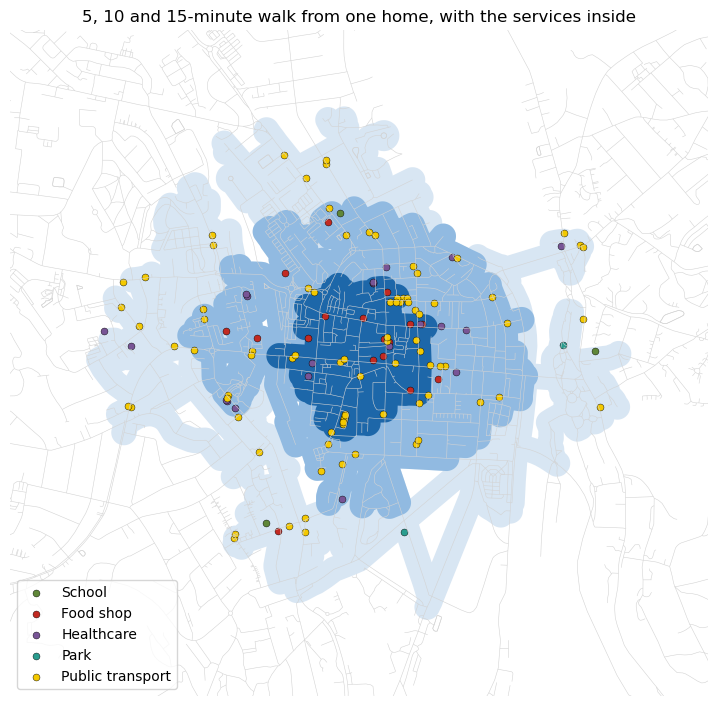

service
Public transport    88
Healthcare          21
Food shop           17
School               3
Park                 2
Name: count, dtype: int64


In [73]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:27700").plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]
for name, colour in zip(SERVICES, ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

#Replicated code to identify all services within 5,10,15 minute walks to services 

In [61]:
iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]

print(inside["service"].value_counts())

#Narrowed it down to only include 15 minutes

service
Public transport    88
Healthcare          21
Food shop           17
School               3
Park                 2
Name: count, dtype: int64


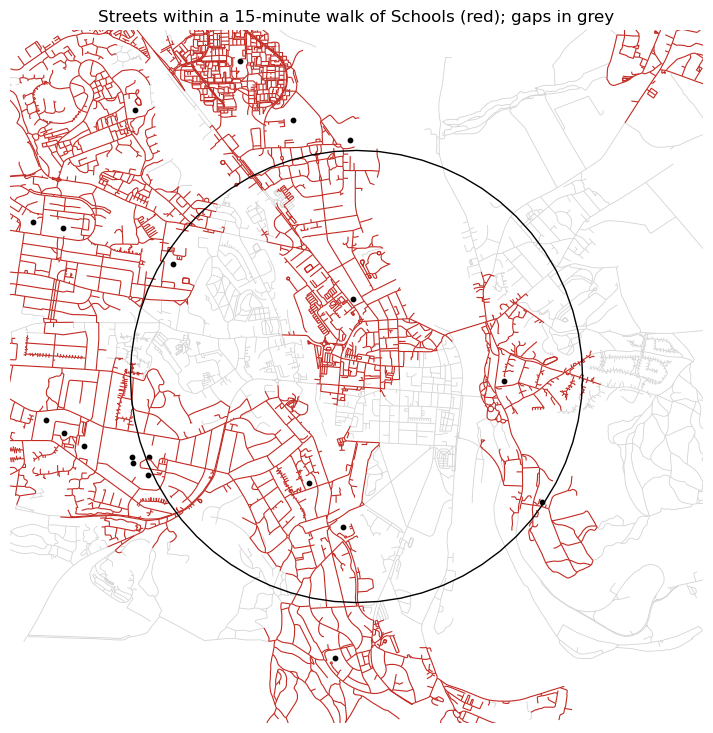

In [66]:
School = services[services["service"] == "School"]
School_nodes = set(ox.distance.nearest_nodes(G_walk, School.geometry.x, School.geometry.y))
dist_to_School = nx.multi_source_dijkstra_path_length(G_walk, School_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_School)) & walk_edges["v"].isin(set(dist_to_School))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
School.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of Schools (red); gaps in grey")
ax.set_axis_off()
plt.show()

#Narrowed it down further to only include Schools within 15 minute walk, buffer remains centre. 

---
## Part 7 · Two-step floating catchment area (2SFCA): park space for everyone?

Being *near* a park is not the whole story. A small park shared by thousands of people offers less than a big park shared by a few. **2SFCA** takes both **supply** and **demand** into account:

- **Step 1**: for each park, divide its **area** (supply) by the number of **people** who can walk to it in 15 minutes (demand). This gives the park space *per person* at that park.
- **Step 2**: for each home, **add up** that value for every park it can walk to in 15 minutes.

The result is the park space (m²) available to each home, with competition from neighbours taken into account.

We don't have population data for every city in the world, so we use **buildings** as a simple stand-in for where people live.

### 7.1 Load the city: St Andrews

The `data` folder has the walk network, parks and buildings for **St Andrews**. Task 7.1 shows how to try any other small city in the world.

**Challenge 6.1 (at home, needs the internet)** — Try any small city in the world. Replace the loading lines in 6.1 with these downloads, then run Part 6 again. Downloads can take a few minutes and may fail if the OpenStreetMap servers are busy; if so, try again later.

In [74]:
CITY = "Leuven, Belgium"  # or "Leuven, Belgium", "Popayán, Colombia", your home town...
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)

#Substituting St Andrews with Leuven Belgium 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

In [79]:
CATCHMENT = 1200        

In [80]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        
demand.head()

#How many buildings are attached to each junction

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


node
20917947      106
20917945      101
16571388       86
20975560       85
1400487492     83
Name: count, dtype: int64

In [81]:
reach = {}          
ratio = {}         

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

#Park space per building 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name   area_m2  m2_per_building
element_type osmid                                                           
way          294999180                Arenbergpark  666172.0           1047.0
             1531841510     Vijvers van Bellefroid  306190.0            843.0
relation     14437364    Provinciedomein Kessel-Lo  524713.0            341.0
way          21562211                      't Fort    9218.0            149.0
             1303111241           Park de Bunswyck   77496.0            103.0
relation     8321099     Alexianenpark Lemmenspark  120681.0             76.0
way          156178756                         NaN   56106.0             63.0
             570459619                Kloostertuin    8950.0             57.0
             294923733                   Lerkeveld   87556.0             41.0
             807559475             Dominicanenberg   28990.0             26.0

In [82]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]      
homes_city["park_access"].describe().round(0)

#Calculations

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


count    6857.0
mean       72.0
std       204.0
min         0.0
25%         4.0
50%        19.0
75%        31.0
max      1106.0
Name: park_access, dtype: float64

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


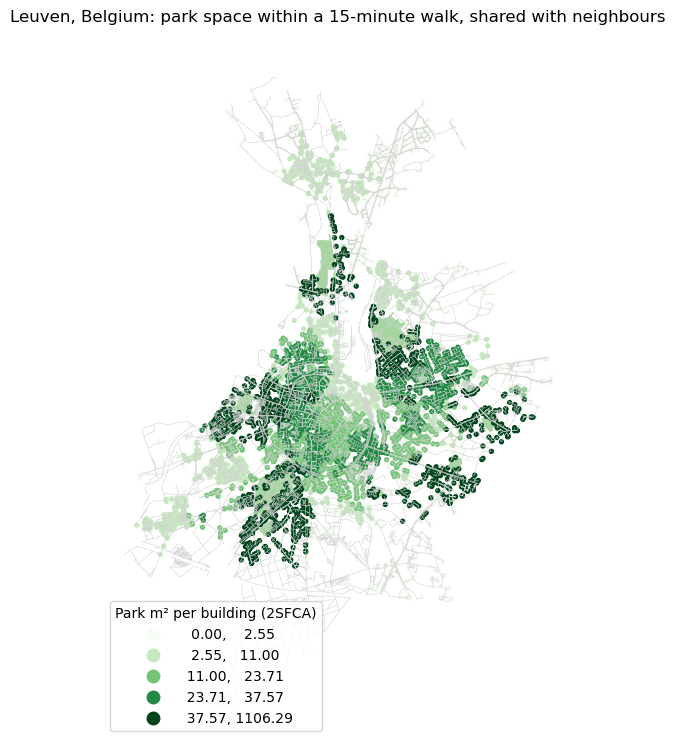

10% of homes have no park within a 15-minute walk


In [83]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

#Plotting map.